### Giving reply uisng sentiment analysis

In [1]:
from langgraph.graph import StateGraph,START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field 
import os

In [2]:
load_dotenv()  # Load environment variables from .env file

True

In [3]:
LLM = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0.2)

In [ ]:
# Define a Pydantic model for the sentiment schema
class SentimentSchema(BaseModel):
    sentiment: Literal["positive", "negative", "neutral"] = Field(..., description="Sentiment of the input text")

In [ ]:
# Define a Pydantic model for the diagnosis schema
class DiagnosisSchema(BaseModel):
    issue_type: Literal["hardware", "software", "network"] = Field(..., description="Type of the issue")
    tone : Literal["angry", "frustrated", "neutral"] = Field(..., description="Tone of the user")
    urgency: Literal["high", "medium", "low"] = Field(..., description="Urgency of the issue")

In [7]:
# Create structured output models for sentiment and diagnosis
structured_model = LLM.with_structured_output(SentimentSchema)
structured_model_diagnosis = LLM.with_structured_output(DiagnosisSchema)

In [12]:
prompt = "I am facing a problem with my laptop. It is not turning on and I have an important meeting in 30 minutes. Please help me urgently."
structured_model_diagnosis = LLM.with_structured_output(DiagnosisSchema)
structured_model_diagnosis.invoke(prompt).issue_type

d:\AIML\Langgraph\L8\python3.11\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


'hardware'

In [13]:
# reviewState
class ReviewState(TypedDict):
    review: str
    sentiment: Literal["positive", "negative", "neutral"]
    diagnosis: DiagnosisSchema
    recommendation: str

In [ ]:
# Defining Node for review state

# Node to find the sentiment of the review
def find_sentiment(state : ReviewState):
    promt = f"Analyze the following review and determine its sentiment (positive, negative): {state['review']}"
    sentiment = structured_model.invoke(promt).sentiment
    return {"sentiment": sentiment}

# Node for check sentiment 
def check_sentiment(state : ReviewState) -> Literal["positive", "negative"]:
    if state['sentiment'] == "positive":
        return "positive"
    elif state['sentiment'] == "negative":
        return "negative"
    else:
        raise ValueError("Sentiment is neutral, cannot proceed with recommendation.")
# Node for postive comment
def positive_recommendation(state : ReviewState):
    prompt = f"Given the review: {state['review']}, provide a positive recommendation for the user."
    recommendation = LLM.invoke(prompt).content
    return {"recommendation": recommendation}

# Node for negative
def negative_recommendation(state : ReviewState):
    prompt = f"Given the review: {state['review']}, provide a negative recommendation for the user."
    recommendation = LLM.invoke(prompt).content
    return {"recommendation": recommendation}

# Node for diagnosis    
def diagnose_issue(state : ReviewState):
    prompt = f"Analyze the following review and provide a diagnosis of the issue: {state['review']}"
    diagnosis = structured_model_diagnosis.invoke(prompt)
    return {"diagnosis": diagnosis}    

In [ ]:
# defining the state graph
graph = StateGraph(ReviewState)

# adding all nodes to the graph
graph.add_node('find_sentiment', find_sentiment)
# graph.add_node('check_sentiment', check_sentiment)
graph.add_node('positive_recommendation', positive_recommendation)
graph.add_node('negative_recommendation', negative_recommendation)
graph.add_node('diagnose_issue', diagnose_issue)

# adding edges to the graph
graph.add_edge(START, 'find_sentiment')
# graph.add_edge('find_sentiment', 'check_sentiment')
graph.add_conditional_edges(
    'find_sentiment',
    check_sentiment,
   {
    "positive": "positive_recommendation",
    "negative": "diagnose_issue",
},
)
graph.add_edge('positive_recommendation', END)
graph.add_edge('diagnose_issue', 'negative_recommendation')
graph.add_edge('negative_recommendation', END)
# graph.add_edge('check_sentiment', 'diagnose_issue')

workflow = graph.compile()    

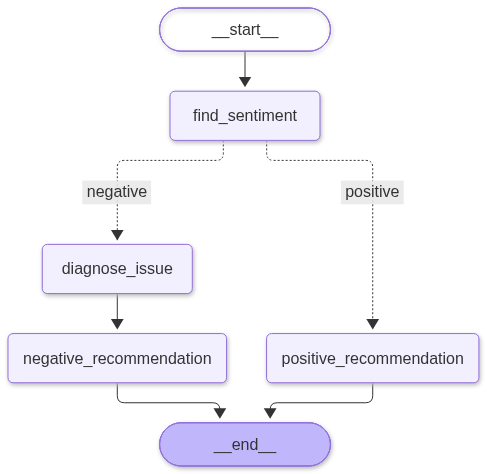

In [25]:
workflow

In [26]:
intial_state = {
    "review": "I am facing a problem with my laptop. It is not turning on and I have an important meeting in 30 minutes. Please help me urgently.",
}
workflow.invoke(intial_state)

d:\AIML\Langgraph\L8\python3.11\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\AIML\Langgraph\L8\python3.11\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(
d:\AIML\Langgraph\L8\python3.11\Lib\site-packages\langchain_google_genai\chat_models.py:3919: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


{'review': 'I am facing a problem with my laptop. It is not turning on and I have an important meeting in 30 minutes. Please help me urgently.',
 'sentiment': 'negative',
 'diagnosis': DiagnosisSchema(issue_type='hardware', tone='frustrated', urgency='high'),
 'recommendation': AIMessage(content=[{'type': 'text', 'text': "Based on your review, here is a recommendation:\n\n**Do not rely on your laptop for this meeting.** Since your laptop will not turn on and you only have 30 minutes left, trying to troubleshoot hardware or software issues right now is extremely risky and likely to fail in time. \n\n**Immediate Action Plan:**\n1. **Switch devices immediately:** Pivot to your smartphone, a tablet, or a colleague's computer to join the meeting. Download the meeting app on your phone right now if you haven't already.\n2. **Call into audio:** If video isn't strictly necessary, use your phone to dial into the meeting audio so you can at least participate in the discussion while you figure ou